# Projet 9 — Analyse agricole par UAV
## Segmentation des cultures avec U-Net et DeepLabV3

### Contexte
Le ministère de l'Agriculture souhaite cartographier les parcelles agricoles et distinguer les différentes classes de végétation à partir d'images prises par drone (UAV).

### Problématique
Les images peuvent présenter des variations de luminosité, des ombres, des zones mélangées et des différences d'apparence entre les cultures et les mauvaises herbes.

### Objectif
Comparer deux architectures de Deep Learning pour la **segmentation sémantique multi-classes** :
- **U-Net** : architecture encodeur-décodeur avec connexions de saut (*skip connections*).
- **DeepLabV3** : architecture utilisant des convolutions dilatées et le module ASPP pour analyser plusieurs échelles.

### Résultats attendus
- Une comparaison quantitative avec l'IoU et le mIoU.
- Une comparaison visuelle des masques prédits.
- Des cartes de segmentation et une estimation de la proportion de pixels par classe.

### À propos des données
Le premier jeu de données utilisé, **`Voxel51/weeds-galore`**, ne contient que 156 images : c'est trop peu pour comparer sérieusement deux réseaux. Nous utilisons maintenant **`Voxel51/CropAndWeed`** (WACV 2023), chargé avec FiftyOne comme avant :
- **8 034 images annotées** (1920 × 1088 pixels), avec un **masque sémantique** pour chaque image ;
- des images prises **du dessus, à environ 1,1 m**, sur des champs réels en Autriche (cultures et mauvaises herbes, avec plusieurs conditions de lumière et de sol) ;
- les masques contiennent **100 classes fines** (espèces et stades de croissance). Nous les regroupons en **5 classes** (section 4.1) ;
- licence **non commerciale** (recherche, enseignement) : usage autorisé pour ce projet.

Le sujet cite aussi DeepWeeds, mais ce jeu de données est annoté pour la **classification** d'images, pas pour la segmentation : il ne convient pas à ce projet.

## Plan du notebook

1. Installation et configuration
2. Importation et configuration
3. Chargement et exploration des données
4. Prétraitement des images et des masques
5. Séparation entraînement / validation / test (par session)
6. Augmentation des données et création des DataLoaders
7. Poids des classes
8. Construction des architectures U-Net et DeepLabV3
9. Fonction de perte et métriques
10. Entraînement
11. Évaluation finale sur le jeu de test
12. Robustesse (conditions réelles et luminosité simulée)
13. Comparaison visuelle des masques
14. Carte finale et proportion par classe
15. Conclusion
16. Système d'inférence (module `inference.py` et interface Streamlit)
17. Exporter les modèles et les résultats

## 1. Installation des bibliothèques
Cette cellule installe les bibliothèques nécessaires. Dans Google Colab, PyTorch est généralement déjà installé.

In [18]:
# À exécuter une seule fois dans l'environnement.
!pip install -q fiftyone segmentation-models-pytorch

## 2. Importation et configuration
Nous fixons une graine aléatoire pour rendre les expériences plus reproductibles.

In [19]:
import re
import random
import copy
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from tqdm.auto import tqdm

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import fiftyone as fo
import fiftyone.utils.huggingface as fouh
import segmentation_models_pytorch as smp

# Fixer les graines aléatoires
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Sélection automatique du matériel
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Matériel utilisé :", DEVICE)

Matériel utilisé : cuda


## 3. Chargement du jeu de données

Nous téléchargeons **CropAndWeed** depuis le Hub de FiftyOne. Chaque échantillon contient une image, plusieurs annotations et, pour la segmentation, un champ de type `Segmentation`.

**Attention :** le téléchargement complet pèse environ **11,6 Go** (8 034 images en haute résolution). Il ne se fait qu'une seule fois : le jeu de données est ensuite conservé (`persistent=True`).

Pour gagner du temps, nous n'utilisons qu'un **sous-ensemble tiré au hasard** (`NOMBRE_IMAGES_MAX`). Mettre `None` pour utiliser les 8 034 images.

In [20]:
NOM_DATASET = "Voxel51/CropAndWeed"
NOMBRE_IMAGES_MAX = None   # None = toutes les images (8 034)

if fo.dataset_exists(NOM_DATASET):
    dataset = fo.load_dataset(NOM_DATASET)      # déjà téléchargé
else:
    dataset = fouh.load_from_hub(NOM_DATASET, persistent=True)

print(dataset)
print("Nombre total d'images :", len(dataset))

Name:        Voxel51/CropAndWeed
Media type:  image
Num samples: 8034
Persistent:  True
Tags:        []
Sample fields:
    id:               fiftyone.core.fields.ObjectIdField
    filepath:         fiftyone.core.fields.StringField
    tags:             fiftyone.core.fields.ListField(fiftyone.core.fields.StringField)
    metadata:         fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.metadata.ImageMetadata)
    created_at:       fiftyone.core.fields.DateTimeField
    last_modified_at: fiftyone.core.fields.DateTimeField
    recording_set:    fiftyone.core.fields.StringField
    session:          fiftyone.core.fields.StringField
    image_id:         fiftyone.core.fields.StringField
    ground_truth:     fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.labels.Detections)
    stem_points:      fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.labels.Keypoints)
    segmentation:     fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.labels.Segmentation)
    m

### 3.1 Identifier le champ contenant les masques

Un masque de segmentation associe à chaque pixel un identifiant de classe. Nous recherchons automatiquement le champ FiftyOne de type `Segmentation`.

In [21]:
champs_segmentation = []

for nom, champ in dataset.get_field_schema().items():
    if (isinstance(champ, fo.EmbeddedDocumentField)
            and champ.document_type == fo.Segmentation):
        champs_segmentation.append(nom)

print("Champs de segmentation trouvés :", champs_segmentation)

if len(champs_segmentation) == 0:
    raise ValueError("Aucun champ de segmentation trouvé dans le dataset.")

CHAMP_MASQUE = champs_segmentation[0]  # Modifier si nécessaire
print("Champ utilisé :", CHAMP_MASQUE)

Champs de segmentation trouvés : ['segmentation']
Champ utilisé : segmentation


### 3.2 Métadonnées : conditions d'acquisition

CropAndWeed indique pour chaque image la lumière (`lighting`), le type de sol (`soil`), l'humidité (`moisture`) et la difficulté de séparer les plantes du sol (`separability`). Ces informations montrent bien la **variabilité** décrite dans la problématique.

In [22]:
schema = dataset.get_field_schema()

for champ in ["recording_set", "lighting", "soil", "moisture", "separability"]:
    if champ in schema:
        print(f"{champ:14s}", dataset.count_values(champ))

recording_set  {'Experimental Set': 4990, 'Application Set': 3044}
lighting       {'sunny': 5819, 'diffuse': 2215}
soil           {'fine': 7910, 'medium': 98, 'coarse': 26}
moisture       {'dry': 4171, 'wet': 1669, 'medium': 2194}
separability   {'hard': 21, 'medium': 309, 'easy': 7704}


### 3.3 Explorer quelques échantillons

Nous affichons quelques images et leurs masques **bruts** (avant regroupement des classes). Cette étape permet de vérifier visuellement que les images et les annotations correspondent bien.

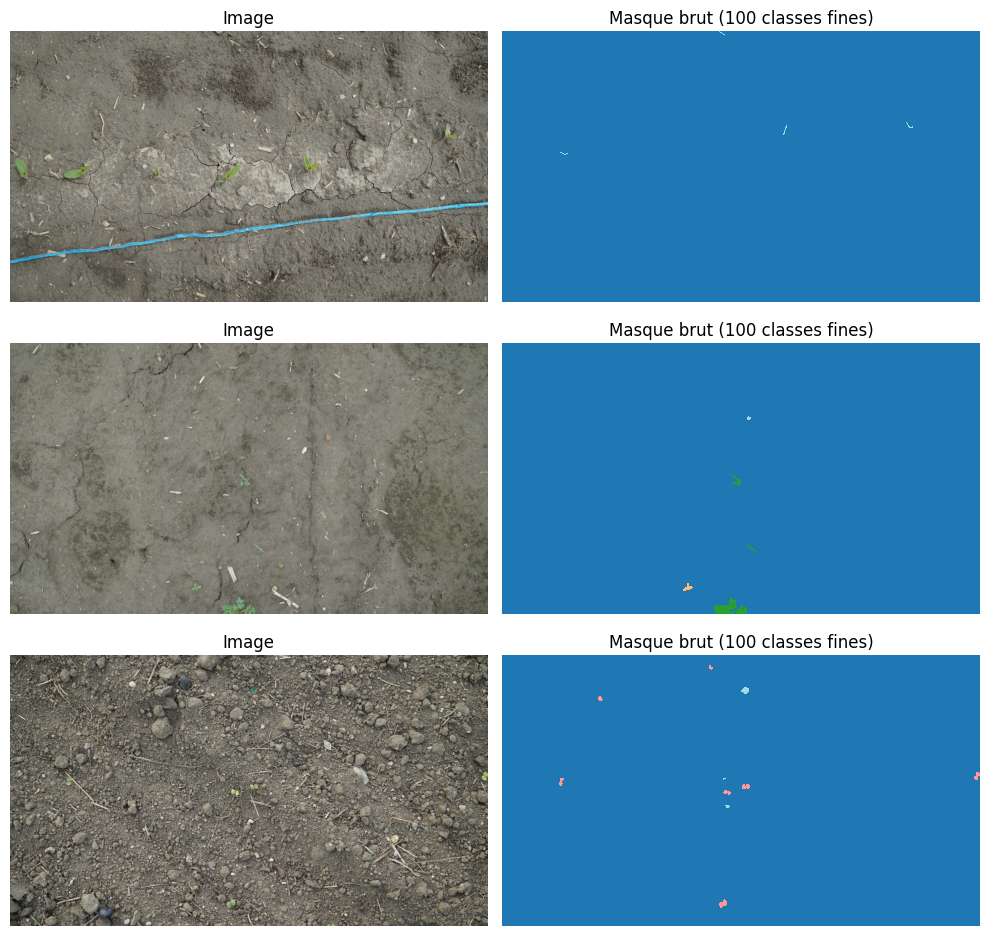

In [23]:
echantillons = dataset.take(3, seed=SEED)

fig, axes = plt.subplots(len(echantillons), 2, figsize=(10, 3.2 * len(echantillons)))
axes = np.array(axes).reshape(-1, 2)

for i, sample in enumerate(echantillons):
    image = Image.open(sample.filepath).convert("RGB")
    masque = sample[CHAMP_MASQUE].get_mask()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(masque, cmap="tab20", interpolation="nearest")
    axes[i, 1].set_title("Masque brut (100 classes fines)")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

### 3.4 Examiner les dimensions et les annotations

Avant le prétraitement, nous examinons les dimensions d'une image et de son masque. Les deux doivent représenter la même zone.

In [24]:
premier = dataset.first()
image_exemple = Image.open(premier.filepath).convert("RGB")
masque_exemple = premier[CHAMP_MASQUE].get_mask()

CIBLES_BRUTES = dataset.mask_targets.get(CHAMP_MASQUE) or dataset.default_mask_targets or {}

print("Dimensions de l'image (largeur, hauteur) :", image_exemple.size)
print("Dimensions du masque (hauteur, largeur)  :", masque_exemple.shape)
print("Type du masque :", masque_exemple.dtype)
print("Valeurs présentes dans ce masque :", np.unique(masque_exemple))
print("Nombre de classes brutes définies :", len(CIBLES_BRUTES))

Dimensions de l'image (largeur, hauteur) : (1920, 1088)
Dimensions du masque (hauteur, largeur)  : (1088, 1920)
Type du masque : uint8
Valeurs présentes dans ce masque : [ 0 48]
Nombre de classes brutes définies : 101


## 4. Prétraitement des données

Le prétraitement se fait en trois étapes :
1. **regrouper** les 100 classes fines en 5 classes utiles ;
2. **redimensionner** les images et les masques en **256 × 256 pixels** ;
3. vérifier la **distribution** des classes et le résultat visuel.

### 4.1 Regroupement des classes

Les masques bruts contiennent 100 classes (espèces et stades de croissance). Beaucoup sont très rares, ce qui rend l'apprentissage difficile. Nous les regroupons en **5 classes** :

| Id | Classe | Contenu |
|----|--------|---------|
| 0 | `background` | sol |
| 1 | `maize` | maïs (culture principale) |
| 2 | `autres_cultures` | betterave, tournesol, haricot, pois, soja, pomme de terre, citrouille… |
| 3 | `mauvaises_herbes` | toutes les autres plantes (adventices) |
| 4 | `vegetation` | classe de secours du jeu de données : plantes trop petites ou ambiguës |

Le regroupement se fait avec les **noms de classes** fournis par le jeu de données. La cellule affiche le tableau complet pour que l'on puisse **vérifier** (et modifier les mots-clés si besoin).

In [25]:
NOMS_CLASSES = ["background", "maize", "autres_cultures", "mauvaises_herbes", "vegetation"]
ID_FOND, ID_MAIS, ID_AUTRES_CULTURES, ID_HERBES, ID_VEGETATION = range(5)
NOMBRE_CLASSES = len(NOMS_CLASSES)

# Couleurs fixes pour toutes les figures du projet
COULEURS_CLASSES = ["#8B5E3C", "#3E8E41", "#1B9AAA", "#D1495B", "#9E9E9E"]
CMAP = ListedColormap(COULEURS_CLASSES)

def afficher_masque(ax, masque):
    ax.imshow(masque, cmap=CMAP, vmin=0, vmax=NOMBRE_CLASSES - 1, interpolation="nearest")
    ax.axis("off")

def legende_classes():
    return [Patch(facecolor=c, label=n) for c, n in zip(COULEURS_CLASSES, NOMS_CLASSES)]

# Mots-clés (en anglais, comme les noms du jeu de données). Modifiables.
def _motif(mots):
    return re.compile(r"\b(?:" + "|".join(mots) + r")s?\b", re.IGNORECASE)

MOTIF_MAIS = _motif(["maize", "corn"])
MOTIF_AUTRES_CULTURES = _motif([
    "beet", "sunflower", "bean", "pea", "soy", "soybean",
    "potato", "pumpkin", "zucchini", "squash", "poppy",
])

def classe_finale(valeur, nom):
    n = str(nom).lower()
    if valeur == 255 or "vegetation" in n:
        return ID_VEGETATION
    if valeur == 0 or "soil" in n or "background" in n:
        return ID_FOND
    if MOTIF_MAIS.search(n):
        return ID_MAIS
    if MOTIF_AUTRES_CULTURES.search(n):
        return ID_AUTRES_CULTURES
    return ID_HERBES

# Table de correspondance : valeur brute (0-255) -> nouvelle classe (0-4)
TABLE = np.full(256, ID_VEGETATION, dtype=np.uint8)   # valeur inconnue -> vegetation
lignes = []
for valeur, nom in sorted(CIBLES_BRUTES.items(), key=lambda kv: int(kv[0])):
    nouvelle = classe_finale(int(valeur), nom)
    TABLE[int(valeur)] = nouvelle
    lignes.append({"Valeur brute": int(valeur), "Nom": nom, "Classe finale": NOMS_CLASSES[nouvelle]})

table_regroupement = pd.DataFrame(lignes)
print("Nombre de classes brutes par classe finale :")
print(table_regroupement["Classe finale"].value_counts().reindex(NOMS_CLASSES).fillna(0).astype(int))

# Sécurité : chaque classe finale doit exister
for i, nom in enumerate(NOMS_CLASSES):
    assert (table_regroupement["Classe finale"] == nom).any(), (
        f"Aucune classe brute ne correspond à '{nom}' : vérifier les noms et les mots-clés."
    )

# Tableau complet à vérifier (faire défiler)
display(table_regroupement)

Nombre de classes brutes par classe finale :
Classe finale
background           1
maize                8
autres_cultures     16
mauvaises_herbes    75
vegetation           1
Name: count, dtype: int64


,Valeur brute,Nom,Classe finale
0,0,Soil,background
1,1,Maize,maize
2,2,Maize two-leaf stage,maize
3,3,Maize four-leaf stage,maize
4,4,Maize six-leaf stage,maize
...,...,...,...
96,96,Field mustard,mauvaises_herbes
97,97,Giant fennel,mauvaises_herbes
98,98,Common horsetail,mauvaises_herbes
99,99,Common dandelion,mauvaises_herbes


### 4.2 Sélection, chargement et redimensionnement

Les images originales font 1920 × 1088 pixels : c'est trop grand pour l'entraînement. Nous les redimensionnons en **256 × 256 pixels** :
- images : interpolation **bilinéaire** ;
- masques : **plus proche voisin**, pour ne pas créer de nouvelles valeurs de classes.

Le regroupement des classes est appliqué **avant** le redimensionnement, à pleine résolution. Nous gardons aussi le nom de la **session** de chaque image (par exemple `ave-0035`) : cela servira à séparer correctement les données (section 5).

Nous conservons les images en RGB (3 canaux).

In [26]:
TAILLE_IMAGE = 256   # augmenter (384, 512) si la mémoire GPU le permet : les petites plantes seront mieux vues

if NOMBRE_IMAGES_MAX is not None and NOMBRE_IMAGES_MAX < len(dataset):
    vue = dataset.take(NOMBRE_IMAGES_MAX, seed=SEED)   # sous-ensemble aléatoire
else:
    vue = dataset

images = []
masques = []
sessions = []

for sample in tqdm(vue, total=len(vue), desc="Chargement"):
    # Charger et redimensionner l'image
    image = Image.open(sample.filepath).convert("RGB")
    taille_originale = image.size                       # (largeur, hauteur)
    image = image.resize((TAILLE_IMAGE, TAILLE_IMAGE), Image.Resampling.BILINEAR)

    # Charger le masque
    masque = sample[CHAMP_MASQUE].get_mask()

    # Si le masque contient plusieurs canaux, conserver le premier
    if masque.ndim == 3:
        masque = masque[:, :, 0]

    # Vérifier que l'image et le masque couvrent la même zone
    assert masque.shape[::-1] == taille_originale, (
        f"Tailles différentes : image {taille_originale}, masque {masque.shape[::-1]}"
    )

    # Regrouper les classes (100 -> 5), puis redimensionner sans mélanger les identifiants
    masque = TABLE[masque.astype(np.uint8)]
    masque_image = Image.fromarray(masque)
    masque_image = masque_image.resize((TAILLE_IMAGE, TAILLE_IMAGE), Image.Resampling.NEAREST)

    images.append(np.asarray(image))
    masques.append(np.asarray(masque_image))

    # Nom de la session : "ave-0035-0007.jpg" -> "ave-0035"
    nom_fichier = sample.filepath.split("/")[-1]
    sessions.append("-".join(nom_fichier.split(".")[0].split("-")[:2]))

images = np.stack(images)
masques = np.stack(masques)
sessions = np.array(sessions)

print("Forme des images :", images.shape)
print("Forme des masques :", masques.shape)
print("Type des images :", images.dtype)
print("Type des masques :", masques.dtype)
print("Valeurs des masques :", np.unique(masques))
print("Nombre de sessions différentes :", len(np.unique(sessions)))

Chargement:   0%|          | 0/8034 [00:00<?, ?it/s]

Forme des images : (8034, 256, 256, 3)
Forme des masques : (8034, 256, 256)
Type des images : uint8
Type des masques : uint8
Valeurs des masques : [0 1 2 3 4]
Nombre de sessions différentes : 929


### 4.3 Explorer la distribution des classes

La distribution des pixels permet de détecter un éventuel déséquilibre. Une classe très fréquente peut dominer l'apprentissage, tandis qu'une classe rare peut être difficile à reconnaître.

Nous calculons ici la proportion de pixels de chaque classe sur l'ensemble des masques pour une **analyse descriptive**. Les poids utilisés pendant l'entraînement seront calculés uniquement à partir des données d'entraînement.

,Classe,Nombre de pixels,Proportion (%)
0,background,509262095,96.72
1,maize,2561028,0.49
2,autres_cultures,6117428,1.16
3,mauvaises_herbes,8337980,1.58
4,vegetation,237693,0.05


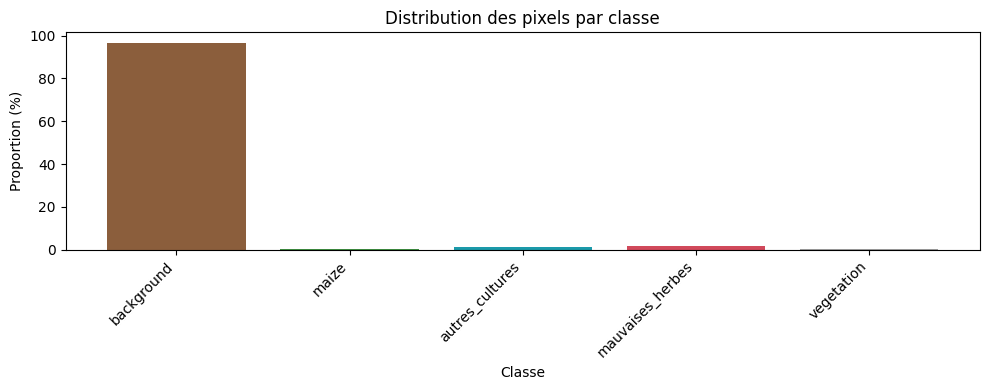

In [27]:
effectifs = np.bincount(masques.ravel(), minlength=NOMBRE_CLASSES)
proportions = effectifs / effectifs.sum()

table_distribution = pd.DataFrame({
    "Classe": NOMS_CLASSES,
    "Nombre de pixels": effectifs,
    "Proportion (%)": proportions * 100
})

display(table_distribution.round(2))

plt.figure(figsize=(10, 4))
plt.bar(NOMS_CLASSES, proportions * 100, color=COULEURS_CLASSES)
plt.title("Distribution des pixels par classe")
plt.ylabel("Proportion (%)")
plt.xlabel("Classe")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 4.4 Vérification visuelle après prétraitement

Nous affichons des images et leurs masques après regroupement et redimensionnement. Nous choisissons ici les images qui contiennent **le plus de plantes**, pour bien voir les classes. Cela permet de contrôler que le prétraitement n'a pas détérioré les annotations.

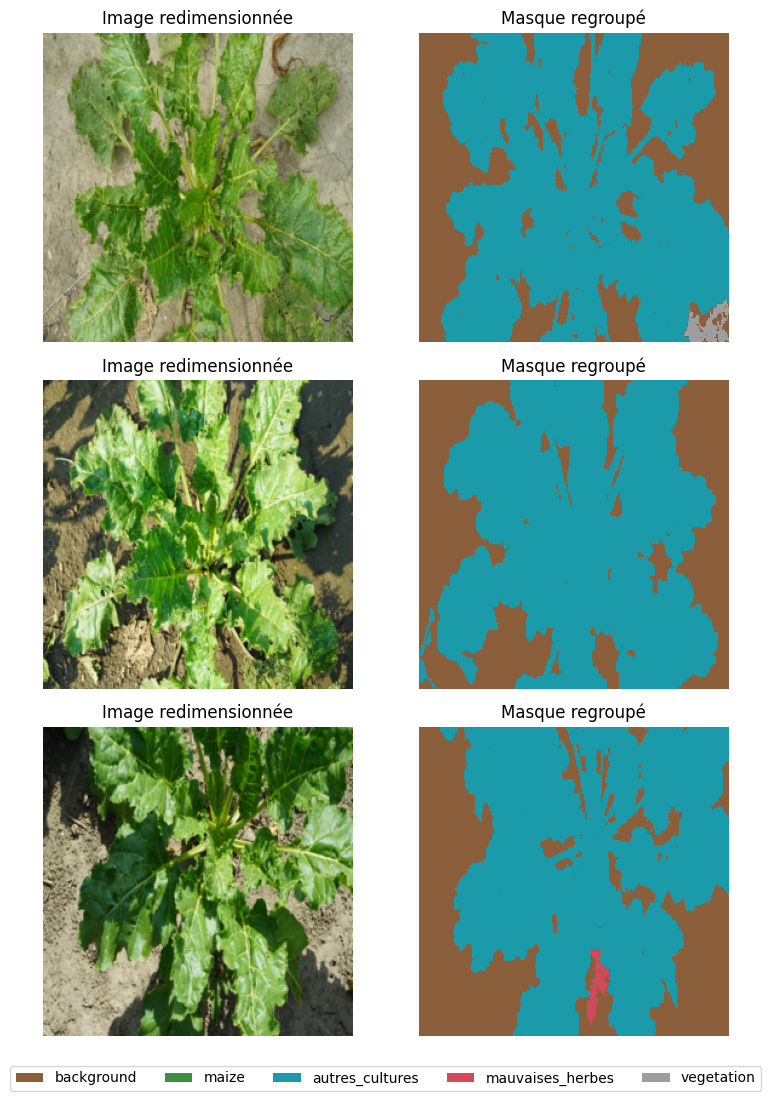

In [28]:
part_plantes = (masques != ID_FOND).mean(axis=(1, 2))
indices_demo = np.argsort(part_plantes)[::-1][:3]      # 3 images avec le plus de plantes

fig, axes = plt.subplots(3, 2, figsize=(8, 11))
for ligne, indice in enumerate(indices_demo):
    axes[ligne, 0].imshow(images[indice])
    axes[ligne, 0].set_title("Image redimensionnée")
    axes[ligne, 0].axis("off")

    afficher_masque(axes[ligne, 1], masques[indice])
    axes[ligne, 1].set_title("Masque regroupé")

fig.legend(handles=legende_classes(), loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## 5. Séparation des données

Nous séparons les images en trois ensembles :
- **Entraînement : 70 %** - apprendre les paramètres du modèle.
- **Validation : 15 %** - suivre les performances et choisir le meilleur modèle.
- **Test : 15 %** - mesurer la performance finale sur des données jamais utilisées pendant l'entraînement.

**Important :** dans CropAndWeed, chaque *session* d'enregistrement (un champ à un moment donné) contient environ 20 images très ressemblantes. Si nous mélangions simplement les images, une image proche d'une image d'entraînement se retrouverait dans le test, et le score serait trop optimiste (*fuite de données*). Nous séparons donc **par session** : toutes les images d'une même session vont dans le même ensemble.

In [29]:
effectif_par_session = Counter(sessions)
liste_sessions = np.array(sorted(effectif_par_session))

rng = np.random.RandomState(SEED)
rng.shuffle(liste_sessions)

seuil_train = 0.70 * len(images)
seuil_val = 0.85 * len(images)

groupe_de_session = {}
cumul = 0
for session in liste_sessions:
    if cumul < seuil_train:
        groupe_de_session[session] = "train"
    elif cumul < seuil_val:
        groupe_de_session[session] = "val"
    else:
        groupe_de_session[session] = "test"
    cumul += effectif_par_session[session]

groupes = np.array([groupe_de_session[s] for s in sessions])
indices_train = np.where(groupes == "train")[0]
indices_val = np.where(groupes == "val")[0]
indices_test = np.where(groupes == "test")[0]

# Aucune session ne doit être présente dans deux ensembles
s_train, s_val, s_test = (set(sessions[i]) for i in (indices_train, indices_val, indices_test))
assert not (s_train & s_val) and not (s_train & s_test) and not (s_val & s_test)

print("Images - entraînement :", len(indices_train), f"({len(s_train)} sessions)")
print("Images - validation   :", len(indices_val), f"({len(s_val)} sessions)")
print("Images - test         :", len(indices_test), f"({len(s_test)} sessions)")

Images - entraînement : 5624 (633 sessions)
Images - validation   : 1210 (145 sessions)
Images - test         : 1200 (151 sessions)


## 6. Augmentation des données et Dataset PyTorch

L'augmentation permet de créer des variantes des images d'entraînement afin d'améliorer la capacité de généralisation du modèle.

Nous appliquons :
- retournement horizontal et vertical ;
- rotations de 90°, 180° ou 270° ;
- variation aléatoire de la luminosité.

La **même transformation** est appliquée à l'image et à son masque.

In [30]:
# Moyenne et écart-type ImageNet, adaptés aux encodeurs pré-entraînés
MOYENNE = np.array([0.485, 0.456, 0.406], dtype=np.float32)
ECART_TYPE = np.array([0.229, 0.224, 0.225], dtype=np.float32)

class JeuSegmentation(Dataset):
    def __init__(self, images, masques, augmentation=False):
        self.images = images
        self.masques = masques
        self.augmentation = augmentation

    def __len__(self):
        return len(self.images)

    def __getitem__(self, indice):
        image = self.images[indice].copy()
        masque = self.masques[indice].copy()

        if self.augmentation:
            if random.random() < 0.5:
                image = np.fliplr(image)
                masque = np.fliplr(masque)

            if random.random() < 0.5:
                image = np.flipud(image)
                masque = np.flipud(masque)

            rotation = random.randint(0, 3)
            image = np.rot90(image, rotation)
            masque = np.rot90(masque, rotation)

            facteur = random.uniform(0.7, 1.3)
            image = np.clip(image.astype(np.float32) * facteur, 0, 255)

        # Normalisation de l'image
        image = image.astype(np.float32) / 255.0
        image = (image - MOYENNE) / ECART_TYPE

        # PyTorch attend les images sous la forme (canaux, hauteur, largeur)
        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float()

        # Le masque doit contenir des entiers de type long
        masque = torch.from_numpy(
            np.ascontiguousarray(masque)
        ).long()

        return image, masque

### 6.1 Créer les ensembles et les DataLoaders

Un `DataLoader` prépare les données par lots (*batches*) pour l'entraînement. Nous mélangeons uniquement les données d'entraînement.

In [31]:
TAILLE_LOT = 8

jeu_train = JeuSegmentation(images[indices_train], masques[indices_train], augmentation=True)
jeu_val = JeuSegmentation(images[indices_val], masques[indices_val], augmentation=False)
jeu_test = JeuSegmentation(images[indices_test], masques[indices_test], augmentation=False)

train_loader = DataLoader(jeu_train, batch_size=TAILLE_LOT, shuffle=True, num_workers=0)
val_loader = DataLoader(jeu_val, batch_size=TAILLE_LOT, shuffle=False, num_workers=0)
test_loader = DataLoader(jeu_test, batch_size=TAILLE_LOT, shuffle=False, num_workers=0)

images_lot, masques_lot = next(iter(train_loader))

print("Forme d'un lot d'images :", images_lot.shape)
print("Forme d'un lot de masques :", masques_lot.shape)
print("Valeurs du masque :", torch.unique(masques_lot))

Forme d'un lot d'images : torch.Size([8, 3, 256, 256])
Forme d'un lot de masques : torch.Size([8, 256, 256])
Valeurs du masque : tensor([0, 1, 2, 3, 4])


### 6.2 Vérifier les augmentations

Nous affichons plusieurs versions augmentées d'une même image (choisie avec beaucoup de plantes). Les formes et les objets du masque doivent rester alignés avec l'image.

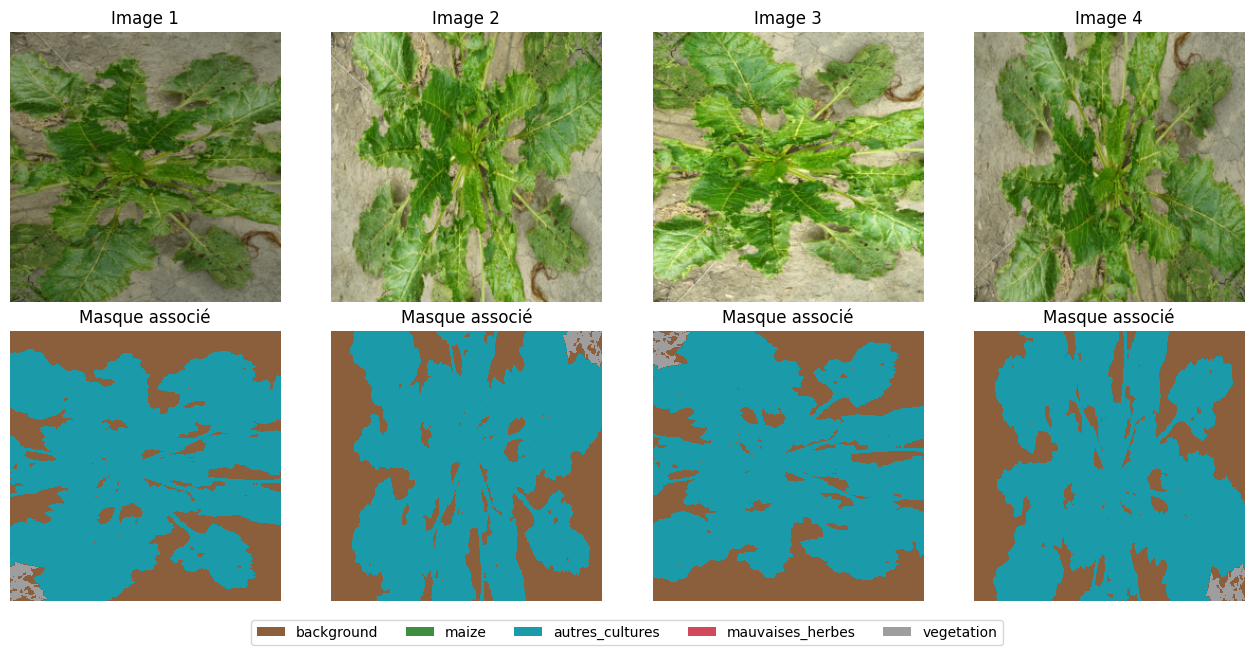

In [32]:
indice_demo = int(indices_demo[0])
jeu_verification = JeuSegmentation(images[indice_demo:indice_demo + 1],
                                   masques[indice_demo:indice_demo + 1],
                                   augmentation=True)

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))

for colonne in range(4):
    image_t, masque_t = jeu_verification[0]

    image_affichee = image_t.numpy().transpose(1, 2, 0)
    image_affichee = (image_affichee * ECART_TYPE + MOYENNE).clip(0, 1)

    axes[0, colonne].imshow(image_affichee)
    axes[0, colonne].set_title(f"Image {colonne + 1}")
    axes[0, colonne].axis("off")

    afficher_masque(axes[1, colonne], masque_t.numpy())
    axes[1, colonne].set_title("Masque associé")

fig.legend(handles=legende_classes(), loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 7. Préparer les poids des classes

Pour limiter l'effet du déséquilibre, nous attribuons un poids plus élevé aux classes moins fréquentes dans l'ensemble d'entraînement.

**Important :** les poids sont calculés uniquement sur les masques d'entraînement afin d'éviter d'utiliser des informations provenant de la validation ou du test.

**Technique utilisée :** *class-weighted loss* (loss pondérée par classe) pour limiter le déséquilibre des classes.

In [33]:
pixels_train = masques[indices_train].ravel()
effectifs_train = np.bincount(pixels_train, minlength=NOMBRE_CLASSES)
frequences_train = effectifs_train / effectifs_train.sum()

# Racine inverse : pondération moins extrême que l'inverse direct
poids_classes = 1.0 / np.sqrt(frequences_train + 1e-6)
poids_classes = poids_classes / poids_classes.mean()
poids_classes = np.clip(poids_classes, 0.2, 5.0)

poids_classes = torch.tensor(poids_classes, dtype=torch.float32)

print(pd.DataFrame({
    "Classe": NOMS_CLASSES,
    "Pixels d'entraînement": effectifs_train,
    "Proportion (%)": (frequences_train * 100).round(2),
    "Poids": poids_classes.numpy().round(3)
}))

             Classe  Pixels d'entraînement  Proportion (%)  Poids
0        background              356242123           96.65  0.200
1             maize                1791503            0.49  0.915
2   autres_cultures                4249577            1.15  0.594
3  mauvaises_herbes                6116706            1.66  0.495
4        vegetation                 174555            0.05  2.930


### Variables prêtes pour la suite

Les cellules ci-dessus fournissent tout ce dont la partie « modèles » a besoin :
- `train_loader`, `val_loader`, `test_loader` : lots de 8 images `[8, 3, 256, 256]` et de masques `[8, 256, 256]` ;
- `NOMBRE_CLASSES` (5) et `NOMS_CLASSES` ;
- `poids_classes` : à utiliser dans la fonction de perte, par exemple `nn.CrossEntropyLoss(weight=poids_classes.to(DEVICE))` ;
- `COULEURS_CLASSES`, `CMAP`, `afficher_masque(...)` et `legende_classes()` : pour garder les mêmes couleurs dans toutes les figures.

In [34]:
print("Nombre de classes :", NOMBRE_CLASSES, NOMS_CLASSES)
print("Lots d'entraînement :", len(train_loader), "| validation :", len(val_loader), "| test :", len(test_loader))
print("Poids des classes :", poids_classes.numpy().round(3))

Nombre de classes : 5 ['background', 'maize', 'autres_cultures', 'mauvaises_herbes', 'vegetation']
Lots d'entraînement : 703 | validation : 152 | test : 150
Poids des classes : [0.2   0.915 0.594 0.495 2.93 ]


## 8. Construction des architectures

Nous comparons deux architectures **avec le même encodeur** (ResNet-34 pré-entraîné sur ImageNet). Ainsi, la différence de performance vient surtout du **décodeur** et de la manière d'agréger le contexte, et non de la qualité des caractéristiques extraites.

| | **U-Net** | **DeepLabV3** |
|---|---|---|
| Principe | Encodeur-décodeur symétrique | Encodeur à convolutions dilatées + module ASPP |
| Contexte multi-échelle | Obtenu par la descente progressive en résolution | Obtenu par ASPP (plusieurs taux de dilatation en parallèle) |
| Détails fins | Très bien conservés grâce aux *skip connections* à chaque niveau | Sortie à plus basse résolution, puis sur-échantillonnage |
| Attendu | Bonnes frontières, petites plantes | Bonne cohérence globale, frontières plus lisses |

Avec 5 624 images d'entraînement, le **transfert d'apprentissage** (poids ImageNet) reste utile : il accélère la convergence et améliore la généralisation.

In [ ]:
import time
import torch.nn.functional as F
import matplotlib.colors as mcolors

ENCODEUR = "resnet34"
POIDS_PREENTRAINES = "imagenet"   # mettre None pour un entraînement depuis zéro

def creer_modele(nom):
    """Crée U-Net ou DeepLabV3 avec le même encodeur."""
    if nom == "U-Net":
        return smp.Unet(encoder_name=ENCODEUR, encoder_weights=POIDS_PREENTRAINES,
                        in_channels=3, classes=NOMBRE_CLASSES)
    if nom == "DeepLabV3":
        return smp.DeepLabV3(encoder_name=ENCODEUR, encoder_weights=POIDS_PREENTRAINES,
                             in_channels=3, classes=NOMBRE_CLASSES)
    raise ValueError(f"Architecture inconnue : {nom}")

NOMS_MODELES = ["U-Net", "DeepLabV3"]

# Vérification rapide : forme de la sortie et nombre de paramètres
x_test = torch.randn(2, 3, TAILLE_IMAGE, TAILLE_IMAGE)
for nom in NOMS_MODELES:
    m = creer_modele(nom)
    m.eval()
    with torch.no_grad():
        sortie = m(x_test)
    nb_params = sum(p.numel() for p in m.parameters()) / 1e6
    print(f"{nom:10s} | sortie : {tuple(sortie.shape)} | paramètres : {nb_params:.1f} M")
    del m

## 9. Fonction de perte et métriques

### 9.1 Fonction de perte
Nous combinons deux pertes complémentaires :
- **Entropie croisée pondérée** : classification de chaque pixel, avec les poids de classes calculés à la section 7.
- **Dice Loss** : mesure le chevauchement entre prédiction et vérité terrain, ce qui est plus proche de l'IoU et moins sensible au déséquilibre.

$$\mathcal{L} = 0{,}5 \cdot \mathcal{L}_{CE\ pondérée} + 0{,}5 \cdot \mathcal{L}_{Dice}$$

### 9.2 Métriques : IoU et mIoU
Pour chaque classe $c$ :

$$IoU_c = \frac{TP_c}{TP_c + FP_c + FN_c}$$

Les IoU sont calculées à partir d'une **matrice de confusion cumulée sur tout l'ensemble** (et non en moyennant des IoU image par image), ce qui évite de biaiser le résultat quand une classe est absente de certaines images.

Nous suivons trois moyennes :
- **mIoU** : moyenne des 5 classes ;
- **mIoU hors fond** : sans le sol, qui représente 96,7 % des pixels ;
- **mIoU plantes** : moyenne sur `maize`, `autres_cultures` et `mauvaises_herbes`. La classe `vegetation` est un « fourre-tout » (plantes trop petites ou ambiguës, 0,05 % des pixels), donc très difficile et peu utile pour l'agriculteur. **Cette dernière métrique sert à choisir le meilleur modèle**, car c'est la plus proche de l'objectif du projet (distinguer cultures et mauvaises herbes).

In [ ]:
IDX_FOND = ID_FOND
IDX_PLANTES = [ID_MAIS, ID_AUTRES_CULTURES, ID_HERBES]
UTILISER_AMP = DEVICE.type == "cuda"   # précision mixte : plus rapide sur GPU


class PerteCombinee(nn.Module):
    def __init__(self, poids_classes, alpha=0.5):
        super().__init__()
        self.alpha = alpha
        self.ce = nn.CrossEntropyLoss(weight=poids_classes)
        self.dice = smp.losses.DiceLoss(mode="multiclass", from_logits=True)

    def forward(self, logits, cibles):
        return self.alpha * self.ce(logits, cibles) + (1 - self.alpha) * self.dice(logits, cibles)


def matrice_confusion(predictions, cibles):
    """Lignes = vérité terrain, colonnes = prédiction."""
    indices = cibles.reshape(-1) * NOMBRE_CLASSES + predictions.reshape(-1)
    return torch.bincount(indices, minlength=NOMBRE_CLASSES ** 2).reshape(NOMBRE_CLASSES, NOMBRE_CLASSES)


def calculer_metriques(cm):
    """IoU par classe, trois mIoU, F1 et exactitude à partir d'une matrice de confusion."""
    cm = cm.double()
    tp = torch.diag(cm)
    fp = cm.sum(dim=0) - tp
    fn = cm.sum(dim=1) - tp
    union = tp + fp + fn

    iou = torch.where(union > 0, tp / union.clamp(min=1), torch.full_like(union, float("nan"))).numpy()
    f1 = torch.where(union > 0, 2 * tp / (2 * tp + fp + fn).clamp(min=1),
                     torch.full_like(union, float("nan"))).numpy()

    hors_fond = [c for c in range(NOMBRE_CLASSES) if c != IDX_FOND]
    return {
        "iou": iou,
        "f1": f1,
        "miou": float(np.nanmean(iou)),
        "miou_sans_fond": float(np.nanmean(iou[hors_fond])),
        "miou_plantes": float(np.nanmean(iou[IDX_PLANTES])),
        "exactitude": float((tp.sum() / cm.sum()).item()),
        "exactitude_de_base": float((cm[IDX_FOND].sum() / cm.sum()).item()),   # tout prédire en « fond »
    }


# Test sur un exemple simple : une prédiction parfaite doit donner IoU = 1
cible_test = torch.randint(0, NOMBRE_CLASSES, (2, 16, 16))
cm_test = matrice_confusion(cible_test, cible_test)
print("mIoU d'une prédiction parfaite :", calculer_metriques(cm_test)["miou"])

## 10. Entraînement

Les deux modèles sont entraînés avec **exactement la même configuration** pour que la comparaison soit équitable :

| Paramètre | Valeur |
|---|---|
| Optimiseur | AdamW (lr = 3e-4, weight decay = 1e-4) |
| Planificateur | Cosine Annealing |
| Perte | 0,5 × CE pondérée + 0,5 × Dice |
| Époques maximum | 20 |
| Arrêt anticipé | 6 époques sans amélioration du mIoU plantes de validation |
| Précision mixte | Oui (sur GPU) |

Le **meilleur modèle** est choisi selon le **mIoU plantes de validation**. Le jeu de test n'est jamais utilisé ici. Les validations et le test viennent de **sessions différentes** de celles de l'entraînement (section 5), donc la sélection du modèle ne subit pas de fuite de données.

**Durée :** avec 5 624 images par époque, comptez environ 1 à 2 minutes par époque sur un GPU de type T4, soit 20 à 40 minutes par modèle. Le meilleur checkpoint est écrit sur le disque dès qu'il s'améliore, donc rien n'est perdu en cas de coupure en fin d'entraînement.

In [ ]:
torch.backends.cudnn.benchmark = True


def evaluer(modele, loader, critere=None):
    """Retourne (perte moyenne ou None, matrice de confusion) sur un DataLoader."""
    modele.eval()
    cm = torch.zeros(NOMBRE_CLASSES, NOMBRE_CLASSES, dtype=torch.long, device=DEVICE)
    perte_totale, nb_images = 0.0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, enabled=UTILISER_AMP):
                logits = modele(x)
            logits = logits.float()
            if critere is not None:
                perte_totale += critere(logits, y).item() * x.size(0)
            nb_images += x.size(0)
            cm += matrice_confusion(logits.argmax(dim=1), y)

    perte = perte_totale / nb_images if critere is not None else None
    return perte, cm.cpu()


def entrainer(nom, epoques=20, lr=3e-4, patience=6):
    # Même initialisation aléatoire pour les deux modèles
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

    fichier = f"meilleur_{nom.lower().replace('-', '')}.pth"
    modele = creer_modele(nom).to(DEVICE)
    critere = PerteCombinee(poids_classes.to(DEVICE))
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=lr, weight_decay=1e-4)
    planificateur = torch.optim.lr_scheduler.CosineAnnealingLR(optimiseur, T_max=epoques)
    scaler = torch.amp.GradScaler("cuda", enabled=UTILISER_AMP)

    historique = {"perte_train": [], "perte_val": [], "miou_val": [],
                  "miou_plantes_val": [], "miou_sans_fond_val": []}
    meilleur_score, meilleur_etat, meilleure_epoque, sans_progres = -1.0, None, 0, 0
    debut = time.time()

    for epoque in range(1, epoques + 1):
        t0 = time.time()

        # ---- Entraînement
        modele.train()
        perte_epoque, nb_images = 0.0, 0
        for x, y in tqdm(train_loader, leave=False, desc=f"{nom} - époque {epoque}"):
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimiseur.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=UTILISER_AMP):
                logits = modele(x)
            perte = critere(logits.float(), y)
            scaler.scale(perte).backward()
            scaler.step(optimiseur)
            scaler.update()
            perte_epoque += perte.item() * x.size(0)
            nb_images += x.size(0)
        planificateur.step()

        # ---- Validation
        perte_val, cm_val = evaluer(modele, val_loader, critere)
        m_val = calculer_metriques(cm_val)

        historique["perte_train"].append(perte_epoque / nb_images)
        historique["perte_val"].append(perte_val)
        historique["miou_val"].append(m_val["miou"])
        historique["miou_plantes_val"].append(m_val["miou_plantes"])
        historique["miou_sans_fond_val"].append(m_val["miou_sans_fond"])

        # ---- Sauvegarde du meilleur modèle (sélection sur le mIoU plantes)
        if m_val["miou_plantes"] > meilleur_score:
            meilleur_score = m_val["miou_plantes"]
            meilleur_etat = copy.deepcopy(modele.state_dict())
            meilleure_epoque = epoque
            sans_progres = 0
            torch.save(meilleur_etat, fichier)
        else:
            sans_progres += 1

        print(f"[{nom}] époque {epoque:02d}/{epoques} | perte train {historique['perte_train'][-1]:.4f} "
              f"| perte val {perte_val:.4f} | mIoU val {m_val['miou']:.4f} "
              f"| mIoU plantes val {m_val['miou_plantes']:.4f}{'  *' if sans_progres == 0 else ''} "
              f"| {time.time() - t0:.0f} s")

        if sans_progres >= patience:
            print(f"[{nom}] arrêt anticipé : pas d'amélioration depuis {patience} époques.")
            break

    duree = time.time() - debut
    modele.load_state_dict(meilleur_etat)
    print(f"[{nom}] meilleur mIoU plantes de validation : {meilleur_score:.4f} (époque {meilleure_epoque}) "
          f"| durée : {duree / 60:.1f} min | fichier : {fichier}\n")
    return modele, historique, meilleure_epoque, duree

In [ ]:
modeles, historiques, meilleures_epoques, durees = {}, {}, {}, {}

for nom in NOMS_MODELES:
    modeles[nom], historiques[nom], meilleures_epoques[nom], durees[nom] = entrainer(nom)

### 10.1 Courbes d'apprentissage

Ces courbes permettent de détecter un **sur-apprentissage** (la perte d'entraînement continue de baisser alors que la perte de validation remonte) et de comparer la vitesse de convergence des deux modèles. La ligne verticale indique l'époque du modèle retenu.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
couleurs_modeles = {"U-Net": "tab:blue", "DeepLabV3": "tab:orange"}

for nom in NOMS_MODELES:
    h = historiques[nom]
    epoques = range(1, len(h["perte_train"]) + 1)
    c = couleurs_modeles[nom]

    axes[0].plot(epoques, h["perte_train"], color=c, linestyle="--", label=f"{nom} - train")
    axes[0].plot(epoques, h["perte_val"], color=c, label=f"{nom} - validation")

    axes[1].plot(epoques, h["miou_plantes_val"], color=c, label=f"{nom} - mIoU plantes")
    axes[1].plot(epoques, h["miou_val"], color=c, linestyle=":", label=f"{nom} - mIoU (5 classes)")
    axes[1].axvline(meilleures_epoques[nom], color=c, alpha=0.3)

axes[0].set_title("Perte (CE pondérée + Dice)")
axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Perte")
axes[1].set_title("mIoU sur la validation")
axes[1].set_xlabel("Époque"); axes[1].set_ylabel("mIoU")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

## 11. Évaluation finale sur le jeu de test

C'est la **première et unique fois** que le jeu de test (1 200 images, 151 sessions jamais vues) est utilisé. Nous calculons :
- l'**IoU par classe**, le **mIoU**, le **mIoU hors fond** et le **mIoU plantes** ;
- le **F1 macro** et l'**exactitude pixel**, à comparer à l'exactitude d'un modèle qui prédirait toujours « sol » (environ 97 %) : l'exactitude seule est donc **peu informative** ici ;
- le **temps d'inférence** par image et le **nombre de paramètres**.

In [ ]:
def mesurer_temps_inference(modele, loader):
    """Temps moyen d'inférence par image (en millisecondes)."""
    modele.eval()
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    debut = time.time()
    nb_images = 0
    with torch.no_grad():
        for x, _ in loader:
            with torch.autocast(device_type=DEVICE.type, enabled=UTILISER_AMP):
                modele(x.to(DEVICE))
            nb_images += x.size(0)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return (time.time() - debut) / nb_images * 1000


resultats = {}
for nom in NOMS_MODELES:
    _, cm = evaluer(modeles[nom], test_loader)
    r = calculer_metriques(cm)
    r["cm"] = cm
    r["params_M"] = sum(p.numel() for p in modeles[nom].parameters()) / 1e6
    r["ms_par_image"] = mesurer_temps_inference(modeles[nom], test_loader)
    resultats[nom] = r

# ---- Tableau IoU par classe
tableau_iou = pd.DataFrame({nom: resultats[nom]["iou"] for nom in NOMS_MODELES}, index=NOMS_CLASSES)
tableau_iou.loc["mIoU"] = [resultats[n]["miou"] for n in NOMS_MODELES]
tableau_iou.loc["mIoU hors fond"] = [resultats[n]["miou_sans_fond"] for n in NOMS_MODELES]
tableau_iou.loc["mIoU plantes"] = [resultats[n]["miou_plantes"] for n in NOMS_MODELES]
print("IoU sur le jeu de test")
display(tableau_iou.round(4))

# ---- Tableau de synthèse
tableau_synthese = pd.DataFrame({
    nom: {
        "mIoU": resultats[nom]["miou"],
        "mIoU plantes": resultats[nom]["miou_plantes"],
        "F1 macro": float(np.nanmean(resultats[nom]["f1"])),
        "Exactitude pixel": resultats[nom]["exactitude"],
        "Exactitude « tout en sol »": resultats[nom]["exactitude_de_base"],
        "Paramètres (M)": resultats[nom]["params_M"],
        "Inférence (ms/image)": resultats[nom]["ms_par_image"],
        "Durée d'entraînement (min)": durees[nom] / 60,
    } for nom in NOMS_MODELES
}).T
print("\nSynthèse comparative")
display(tableau_synthese.round(4))

# ---- Graphique IoU par classe
tableau_iou.iloc[:NOMBRE_CLASSES].plot(kind="bar", figsize=(11, 4.5), color=["tab:blue", "tab:orange"])
plt.title("IoU par classe sur le jeu de test")
plt.ylabel("IoU"); plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 11.1 Matrices de confusion

Chaque ligne est normalisée : la case $(i, j)$ indique la proportion de pixels de la classe réelle $i$ prédits comme classe $j$. La diagonale correspond au **rappel** de chaque classe. Les confusions les plus intéressantes ici sont entre `autres_cultures` et `mauvaises_herbes` (une jeune betterave ressemble à une adventice) et entre les plantes et `vegetation`.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, nom in zip(axes, NOMS_MODELES):
    cm = resultats[nom]["cm"].numpy().astype(np.float64)
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{nom} - matrice de confusion normalisée")
    ax.set_xticks(range(NOMBRE_CLASSES)); ax.set_yticks(range(NOMBRE_CLASSES))
    ax.set_xticklabels(NOMS_CLASSES, rotation=45, ha="right")
    ax.set_yticklabels(NOMS_CLASSES)
    ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle")

    for i in range(NOMBRE_CLASSES):
        for j in range(NOMBRE_CLASSES):
            ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=8)

fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02)
plt.show()

## 12. Robustesse aux conditions d'acquisition

La problématique parle de **variabilité** : luminosité, ombres, sols différents. CropAndWeed fournit pour chaque image la **lumière** (`lighting` : *sunny* avec ombres marquées, ou *diffuse*), l'**humidité du sol** (`moisture`) et le type de sol. Nous mesurons donc la performance du modèle dans chacune de ces conditions **réelles** sur le jeu de test.

In [ ]:
def evaluer_indices(modele, ids):
    """Métriques du modèle sur un sous-ensemble d'images (indices dans `images`)."""
    loader = DataLoader(JeuSegmentation(images[ids], masques[ids]),
                        batch_size=TAILLE_LOT * 2, shuffle=False, num_workers=0)
    _, cm = evaluer(modele, loader)
    return calculer_metriques(cm)


schema = dataset.get_field_schema()
conditions = {champ: np.array([str(v) for v in vue.values(champ)])
              for champ in ["lighting", "moisture"] if champ in schema}

lignes = []
for champ, valeurs in conditions.items():
    for categorie in sorted(set(valeurs[indices_test])):
        ids = indices_test[valeurs[indices_test] == categorie]
        if len(ids) < 20:        # trop peu d'images pour conclure
            continue
        ligne = {"Condition": f"{champ} = {categorie}", "Images de test": len(ids)}
        for nom in NOMS_MODELES:
            ligne[f"{nom} - mIoU plantes"] = evaluer_indices(modeles[nom], ids)["miou_plantes"]
        lignes.append(ligne)

tableau_conditions = pd.DataFrame(lignes)
display(tableau_conditions.round(4))

### 12.1 Variation de luminosité simulée

En complément, nous modifions artificiellement la luminosité des images de test (de 50 % à 150 %). Un modèle robuste doit voir son mIoU diminuer lentement. Cette expérience simule un changement **global** de luminosité, pas de vraies ombres portées.

In [ ]:
def evaluer_luminosite(modele, facteur, taille_bloc=200):
    """mIoU plantes sur le jeu de test avec une luminosité multipliée par `facteur` (par blocs, pour économiser la mémoire)."""
    cm = torch.zeros(NOMBRE_CLASSES, NOMBRE_CLASSES, dtype=torch.long)
    for debut in range(0, len(indices_test), taille_bloc):
        ids = indices_test[debut:debut + taille_bloc]
        images_modifiees = np.clip(images[ids].astype(np.float32) * facteur, 0, 255).astype(np.uint8)
        loader = DataLoader(JeuSegmentation(images_modifiees, masques[ids]),
                            batch_size=TAILLE_LOT * 2, shuffle=False, num_workers=0)
        cm += evaluer(modele, loader)[1]
    return calculer_metriques(cm)["miou_plantes"]


facteurs = [0.5, 0.7, 0.85, 1.0, 1.15, 1.3, 1.5]
robustesse = {nom: [evaluer_luminosite(modeles[nom], f) for f in facteurs] for nom in NOMS_MODELES}

display(pd.DataFrame(robustesse, index=[f"x{f}" for f in facteurs]).round(4))

plt.figure(figsize=(8, 4.5))
for nom in NOMS_MODELES:
    plt.plot(facteurs, robustesse[nom], marker="o", label=nom, color=couleurs_modeles[nom])
plt.axvline(1.0, color="gray", linestyle="--", alpha=0.5)
plt.title("mIoU plantes selon la luminosité des images de test")
plt.xlabel("Facteur de luminosité (1.0 = image originale)")
plt.ylabel("mIoU plantes")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 13. Comparaison visuelle des masques prédits

Nous affichons les images de test contenant le plus de classes différentes (donc les plus difficiles), avec la vérité terrain et les prédictions des deux modèles. Les **cartes d'erreurs** (en rouge) montrent les pixels mal classés.

In [ ]:
PALETTE = np.array([mcolors.to_rgb(c) for c in COULEURS_CLASSES], dtype=np.float32)
LEGENDE = legende_classes()


def colorier(masque):
    return PALETTE[masque]


def predire_masques(modele, images_np, taille_lot=16):
    """Retourne les masques prédits (N, H, W) pour un tableau d'images uint8."""
    faux_masques = np.zeros(images_np.shape[:3], dtype=np.uint8)
    loader = DataLoader(JeuSegmentation(images_np, faux_masques, augmentation=False),
                        batch_size=taille_lot, shuffle=False, num_workers=0)
    sorties = []
    modele.eval()
    with torch.no_grad():
        for x, _ in loader:
            with torch.autocast(device_type=DEVICE.type, enabled=UTILISER_AMP):
                logits = modele(x.to(DEVICE))
            sorties.append(logits.float().argmax(dim=1).cpu().numpy().astype(np.uint8))
    return np.concatenate(sorties)


def miou_image(prediction, verite):
    cm = matrice_confusion(torch.from_numpy(prediction).long(), torch.from_numpy(verite).long())
    return calculer_metriques(cm)["miou"]


images_test = images[indices_test]
masques_test = masques[indices_test]
predictions_test = {nom: predire_masques(modeles[nom], images_test) for nom in NOMS_MODELES}

# Images les plus riches en classes (puis en pixels de plantes)
score = [(len(np.unique(m)), int((m != IDX_FOND).sum())) for m in masques_test]
indices_affichage = sorted(range(len(masques_test)), key=lambda i: score[i], reverse=True)[:4]

fig, axes = plt.subplots(len(indices_affichage), 4, figsize=(15, 3.8 * len(indices_affichage)))
for ligne, i in enumerate(indices_affichage):
    axes[ligne, 0].imshow(images_test[i])
    axes[ligne, 0].set_title("Image UAV")
    axes[ligne, 1].imshow(colorier(masques_test[i]), interpolation="nearest")
    axes[ligne, 1].set_title("Vérité terrain")
    for colonne, nom in enumerate(NOMS_MODELES, start=2):
        axes[ligne, colonne].imshow(colorier(predictions_test[nom][i]), interpolation="nearest")
        axes[ligne, colonne].set_title(f"{nom} (mIoU image : {miou_image(predictions_test[nom][i], masques_test[i]):.2f})")
    for ax in axes[ligne]:
        ax.axis("off")

fig.legend(handles=LEGENDE, loc="lower center", ncol=NOMBRE_CLASSES, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

In [ ]:
# Cartes d'erreurs : en rouge, les pixels mal classés
fig, axes = plt.subplots(len(indices_affichage), 3, figsize=(11, 3.6 * len(indices_affichage)))
for ligne, i in enumerate(indices_affichage):
    axes[ligne, 0].imshow(images_test[i])
    axes[ligne, 0].set_title("Image UAV")
    for colonne, nom in enumerate(NOMS_MODELES, start=1):
        erreur = predictions_test[nom][i] != masques_test[i]
        axes[ligne, colonne].imshow(erreur, cmap="Reds", vmin=0, vmax=1, interpolation="nearest")
        axes[ligne, colonne].set_title(f"{nom} - erreurs ({erreur.mean() * 100:.1f} % des pixels)")
    for ax in axes[ligne]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## 14. Carte finale et estimation de la proportion par classe

Livrable final : une **carte de segmentation** exploitable par le ministère.

1. Le **meilleur modèle** (selon le mIoU plantes de test) est sélectionné automatiquement.
2. Les cartes sont produites à la **résolution originale** (1920 × 1088) : les scores du modèle sont agrandis avant de choisir la classe, ce qui donne des contours plus lisses qu'un simple agrandissement du masque.
3. Nous estimons la **proportion de pixels par classe** et un **taux d'infestation** :

$$\text{Taux d'infestation} = \frac{\text{pixels de mauvaises herbes}}{\text{pixels de cultures (maïs + autres cultures)} + \text{pixels de mauvaises herbes}}$$

La classe `vegetation` (ambiguë) est exclue de ce calcul. Ces proportions sont des **proportions de surface relatives** : elles ne peuvent pas être converties en m² sans la résolution au sol de chaque prise de vue.

In [ ]:
MEILLEUR_MODELE = max(NOMS_MODELES, key=lambda n: resultats[n]["miou_plantes"])
modele_final = modeles[MEILLEUR_MODELE]
print("Modèle retenu pour la carte finale :", MEILLEUR_MODELE,
      f"(mIoU plantes test = {resultats[MEILLEUR_MODELE]['miou_plantes']:.4f})")

chemins_images = vue.values("filepath")   # même ordre que le tableau `images`


def carte_pleine_resolution(modele, chemin):
    """Segmente une image à sa résolution d'origine."""
    image = Image.open(chemin).convert("RGB")
    largeur, hauteur = image.size
    petite = np.asarray(image.resize((TAILLE_IMAGE, TAILLE_IMAGE), Image.Resampling.BILINEAR))

    x = (petite.astype(np.float32) / 255.0 - MOYENNE) / ECART_TYPE
    x = torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1))).float().unsqueeze(0).to(DEVICE)

    modele.eval()
    with torch.no_grad():
        logits = modele(x).float()
        logits = F.interpolate(logits, size=(hauteur, largeur), mode="bilinear", align_corners=False)
    return np.asarray(image), logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)


def superposer(image, masque, alpha=0.5):
    """Superpose les classes sur l'image ; le fond reste transparent."""
    image_f = image.astype(np.float32) / 255.0
    resultat = np.where((masque != IDX_FOND)[..., None],
                        (1 - alpha) * image_f + alpha * colorier(masque), image_f)
    return np.clip(resultat, 0, 1)


# Trois images de test avec le plus de pixels de mauvaises herbes
ordre = sorted(range(len(masques_test)), key=lambda i: int((masques_test[i] == ID_HERBES).sum()), reverse=True)[:3]

fig, axes = plt.subplots(len(ordre), 3, figsize=(16, 3.2 * len(ordre) + 0.8))
for ligne, i in enumerate(ordre):
    chemin = chemins_images[indices_test[i]]
    image_originale, carte = carte_pleine_resolution(modele_final, chemin)

    axes[ligne, 0].imshow(image_originale);                           axes[ligne, 0].set_title("Image UAV originale")
    axes[ligne, 1].imshow(colorier(carte), interpolation="nearest");  axes[ligne, 1].set_title(f"Carte de segmentation ({MEILLEUR_MODELE})")
    axes[ligne, 2].imshow(superposer(image_originale, carte));        axes[ligne, 2].set_title("Superposition")
    for ax in axes[ligne]:
        ax.axis("off")

    if ligne == 0:
        Image.fromarray((colorier(carte) * 255).astype(np.uint8)).save("carte_segmentation_exemple.png")

fig.legend(handles=LEGENDE, loc="lower center", ncol=NOMBRE_CLASSES, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("carte_finale.png", dpi=130, bbox_inches="tight")
plt.show()
print("Fichiers enregistrés : carte_finale.png, carte_segmentation_exemple.png")

In [ ]:
# Proportion de pixels par classe : prédiction du meilleur modèle vs vérité terrain (ensemble de test)
cm_final = resultats[MEILLEUR_MODELE]["cm"].numpy().astype(np.float64)
pixels_reels = cm_final.sum(axis=1)
pixels_predits = cm_final.sum(axis=0)

table_proportions = pd.DataFrame({
    "Classe": NOMS_CLASSES,
    "Vérité terrain (%)": pixels_reels / pixels_reels.sum() * 100,
    f"Prédiction {MEILLEUR_MODELE} (%)": pixels_predits / pixels_predits.sum() * 100,
})
table_proportions["Écart (points)"] = table_proportions.iloc[:, 2] - table_proportions.iloc[:, 1]
display(table_proportions.round(2))


def taux_infestation(pixels):
    cultures = pixels[ID_MAIS] + pixels[ID_AUTRES_CULTURES]
    return pixels[ID_HERBES] / (cultures + pixels[ID_HERBES]) * 100

print(f"Taux d'infestation réel      : {taux_infestation(pixels_reels):.1f} %")
print(f"Taux d'infestation prédit    : {taux_infestation(pixels_predits):.1f} %")

# Graphique hors fond (le fond écraserait les autres barres)
hors_fond = [c for c in range(NOMBRE_CLASSES) if c != IDX_FOND]
position = np.arange(len(hors_fond))
plt.figure(figsize=(10, 4.5))
plt.bar(position - 0.2, (pixels_reels / pixels_reels.sum() * 100)[hors_fond], width=0.4,
        label="Vérité terrain", color="gray")
plt.bar(position + 0.2, (pixels_predits / pixels_predits.sum() * 100)[hors_fond], width=0.4,
        label=f"Prédiction ({MEILLEUR_MODELE})", color=couleurs_modeles[MEILLEUR_MODELE])
plt.xticks(position, [NOMS_CLASSES[c] for c in hors_fond], rotation=30, ha="right")
plt.ylabel("Proportion de pixels (%)")
plt.title("Proportion estimée par classe (hors fond) - jeu de test")
plt.legend(); plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 15. Conclusion

### Résultats
La cellule ci-dessous résume automatiquement les résultats obtenus lors de l'exécution (le texte s'adapte aux valeurs réelles).

In [ ]:
autre = [n for n in NOMS_MODELES if n != MEILLEUR_MODELE][0]
r_b, r_a = resultats[MEILLEUR_MODELE], resultats[autre]

print(f"Modèle le plus performant (mIoU plantes, test) : {MEILLEUR_MODELE}")
print(f"  - mIoU plantes   : {r_b['miou_plantes']:.4f} contre {r_a['miou_plantes']:.4f} pour {autre}")
print(f"  - mIoU (5 cl.)   : {r_b['miou']:.4f} contre {r_a['miou']:.4f}")
print(f"  - exactitude pixel : {r_b['exactitude']:.3f} (référence « tout en sol » : {r_b['exactitude_de_base']:.3f})")

iou_plantes = {NOMS_CLASSES[c]: r_b["iou"][c] for c in IDX_PLANTES}
print(f"  - classe de plante la mieux segmentée : {max(iou_plantes, key=iou_plantes.get)} "
      f"(IoU = {max(iou_plantes.values()):.3f})")
print(f"  - classe de plante la plus difficile  : {min(iou_plantes, key=iou_plantes.get)} "
      f"(IoU = {min(iou_plantes.values()):.3f})")
print(f"  - taux d'infestation : réel {taux_infestation(pixels_reels):.1f} % | prédit {taux_infestation(pixels_predits):.1f} %")
print(f"  - inférence : {resultats['U-Net']['ms_par_image']:.1f} ms/image (U-Net) "
      f"contre {resultats['DeepLabV3']['ms_par_image']:.1f} ms/image (DeepLabV3)")

ecart_robustesse = {n: robustesse[n][facteurs.index(1.0)] - min(robustesse[n]) for n in NOMS_MODELES}
plus_robuste = min(ecart_robustesse, key=ecart_robustesse.get)
print(f"  - modèle le plus stable face aux variations de luminosité : {plus_robuste} "
      f"(perte maximale de mIoU plantes = {ecart_robustesse[plus_robuste]:.3f})")

### Discussion

- **Déséquilibre des classes** : le sol occupe 96,7 % des pixels et les plantes moins de 3,3 %. L'exactitude pixel est donc presque inutile : nous utilisons une perte pondérée, une Dice Loss, et le **mIoU plantes** comme métrique de référence.
- **Classe `vegetation`** : c'est la classe de secours du jeu de données (plantes trop petites ou ambiguës). Sa segmentation est intrinsèquement difficile, c'est pourquoi elle est exclue du mIoU plantes et du taux d'infestation.
- **Cultures et mauvaises herbes** : les jeunes plants de culture (betterave, tournesol, haricot...) ressemblent beaucoup aux adventices au même stade. Les matrices de confusion montrent si le modèle les mélange.
- **Compromis entre les architectures** : U-Net conserve mieux les détails fins grâce à ses *skip connections*, ce qui aide pour les petites plantes ; DeepLabV3 capte davantage de contexte grâce à ASPP, mais sa sortie à plus faible résolution peut lisser les petits objets.
- **Conditions réelles** : la section 12 compare la performance en lumière *sunny* (ombres marquées) et *diffuse*, et selon l'humidité du sol.

### Limites
- **Redimensionnement à 256 × 256** : les images 1920 × 1088 sont réduites d'un facteur 7,5 en largeur et 4,25 en hauteur, et leurs proportions sont déformées. Les petites plantes perdent beaucoup de détails.
- **Une seule graine et une seule séparation** : pas d'intervalle de confiance. La séparation se fait cependant **par session**, ce qui évite la fuite de données entre images voisines.
- **Regroupement des classes** : 100 classes fines sont réduites à 5. Le modèle ne distingue donc pas les espèces d'adventices.
- **Jeu de données** : images prises à environ 1,1 m, sur des champs autrichiens. Le modèle ne se généralise pas directement à d'autres altitudes, cultures ou régions.
- **Licence** : CropAndWeed est sous licence non commerciale (recherche et enseignement).

### Perspectives
1. Entraîner à **résolution plus élevée** (384 ou 512) ou sur des **tuiles** de l'image d'origine pour mieux voir les petites plantes.
2. **Validation croisée par session** ou plusieurs graines pour obtenir des moyennes et des écarts-types.
3. Essai de **DeepLabV3+** ou d'encodeurs plus récents (EfficientNet, SegFormer), et d'une perte **focale**.
4. Segmentation par **espèce** d'adventices (classes fines du jeu de données) pour recommander un traitement adapté.
5. Évaluation sur un **autre jeu de données** (par exemple des images de drone à plus haute altitude) pour mesurer la généralisation.

### Livrables produits par ce notebook
| Livrable demandé | Où le trouver |
|---|---|
| Comparaison détaillée U-Net vs DeepLabV3 | Sections 10 à 13 (courbes, IoU par classe, matrices de confusion, robustesse, masques) |
| Carte finale | Section 14 (`carte_finale.png`, `carte_segmentation_exemple.png`) |
| Modèles entraînés | `meilleur_unet.pth`, `meilleur_deeplabv3.pth` |
| Système d'inférence | Section 16 (`inference.py`, `app.py`) |

## 16. Système d'inférence

Nous transformons le notebook en **outil réutilisable** : un module `inference.py` charge un modèle entraîné et segmente de nouvelles images sans repasser par l'entraînement.

| Fonction | Description |
|---|---|
| Image ou dossier | Traitement d'une image ou de toutes les images d'un dossier |
| **Tuilage** | Les grandes images (mosaïques de drone) sont découpées en tuiles de 1088 × 1920 px (la taille des images d'entraînement), avec recouvrement et fusion pondérée pour éviter les coutures visibles |
| TTA (optionnel) | Moyenne des prédictions sur l'image et ses versions retournées |
| Sorties | Masque de classes (PNG), carte colorée, superposition, statistiques (JSON) et `resume.csv` pour un dossier |
| Indicateurs | Proportion de pixels par classe, taux d'infestation, confiance moyenne |
| Interface web | Application Streamlit (`app.py`) : dépôt d'images, cartes, statistiques, téléchargements |

Le prétraitement (redimensionnement 256 × 256, normalisation ImageNet) est **identique à celui de l'entraînement**. Un décalage à cet endroit est la cause la plus fréquente de mauvaises prédictions en production.

La cellule suivante écrit le module sur le disque. Le même fichier s'utilise aussi en ligne de commande en dehors du notebook :
```
python inference.py dossier_images/ --poids meilleur_unet.pth --architecture unet
```

In [ ]:
%%writefile inference.py
#!/usr/bin/env python3
"""
Système d'inférence - Segmentation agricole UAV (U-Net / DeepLabV3)

Fonctionnalités
  - charge un modèle entraîné dans le notebook (meilleur_unet.pth / meilleur_deeplabv3.pth)
  - segmente une image, un dossier d'images, ou une grande image par tuiles (mosaïque de drone)
  - produit : masque de classes (PNG), carte colorée, superposition, statistiques JSON
  - estime la proportion de pixels par classe et le taux d'infestation
  - interface web : voir app.py (Streamlit)

Exemples
  python inference.py parcelle.jpg --poids meilleur_unet.pth --architecture unet
  python inference.py dossier_images/ --poids meilleur_deeplabv3.pth --architecture deeplabv3 --tta
  python inference.py mosaique.tif --poids meilleur_unet.pth --tuile 1088 1920 --recouvrement 0.25
  streamlit run app.py          # interface web
"""
from __future__ import annotations

import argparse
import csv
import json
import time
from dataclasses import dataclass
from pathlib import Path

import numpy as np
from PIL import Image

import torch
import torch.nn.functional as F
import segmentation_models_pytorch as smp

# --------------------------------------------------------------------------- Configuration
# Doit être identique à celle utilisée à l'entraînement dans le notebook.
NOMS_CLASSES_DEFAUT = ["background", "maize", "autres_cultures", "mauvaises_herbes", "vegetation"]
# Classes comptées comme culture / comme adventices pour le taux d'infestation
# (la classe "vegetation" est ambiguë : elle est exclue du calcul)
CULTURES = ("maize", "autres_cultures")
ADVENTICES = ("mauvaises_herbes",)
TAILLE_MODELE = 256
MOYENNE = np.array([0.485, 0.456, 0.406], dtype=np.float32)
ECART_TYPE = np.array([0.229, 0.224, 0.225], dtype=np.float32)
EXTENSIONS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}

COULEURS_BASE = ["#8B5E3C", "#3E8E41", "#1B9AAA", "#D1495B", "#9E9E9E"]   # identiques au notebook


def palette(n):
    """Tableau (n, 3) de couleurs RGB en [0, 1]."""
    if n <= len(COULEURS_BASE):
        hexes = COULEURS_BASE[:n]
        return np.array([[int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)] for h in hexes], dtype=np.float32)
    import matplotlib.pyplot as plt
    return np.array([plt.cm.tab20(i)[:3] for i in range(n)], dtype=np.float32)


# --------------------------------------------------------------------------- Fonctions utilitaires (sans PyTorch)
def positions(longueur, taille, pas):
    """Positions de départ des tuiles le long d'un axe ; la dernière est alignée sur le bord."""
    if longueur <= taille:
        return [0]
    pos = list(range(0, longueur - taille + 1, pas))
    if pos[-1] != longueur - taille:
        pos.append(longueur - taille)
    return pos


def fenetre(hauteur, largeur):
    """Fenêtre de pondération (forte au centre, faible sur les bords) pour fusionner les tuiles."""
    wy = np.hanning(hauteur + 2)[1:-1]
    wx = np.hanning(largeur + 2)[1:-1]
    return (np.outer(wy, wx) + 1e-3).astype(np.float32)


def normaliser_tuile(taille_tuile):
    """None, un entier (tuile carrée) ou (hauteur, largeur) -> None ou (hauteur, largeur)."""
    if taille_tuile is None:
        return None
    if isinstance(taille_tuile, (int, np.integer)):
        resultat = (int(taille_tuile), int(taille_tuile))
    else:
        hauteur, largeur = taille_tuile
        resultat = (int(hauteur), int(largeur))
    return resultat if min(resultat) > 0 else None


def calculer_stats(masque, noms):
    """Pixels et proportions par classe, taux d'infestation = adventices / (cultures + adventices)."""
    n = len(noms)
    effectifs = np.bincount(masque.ravel(), minlength=n).astype(np.int64)
    total = int(effectifs.sum())

    cultures = sum(int(effectifs[noms.index(c)]) for c in CULTURES if c in noms)
    adventices = sum(int(effectifs[noms.index(c)]) for c in ADVENTICES if c in noms)
    plantes = cultures + adventices
    taux = round(100.0 * adventices / plantes, 3) if plantes > 0 else None

    return {
        "dimensions": [int(masque.shape[1]), int(masque.shape[0])],
        "pixels": {noms[i]: int(effectifs[i]) for i in range(n)},
        "proportion_pct": {noms[i]: round(100.0 * float(effectifs[i]) / total, 3) for i in range(n)},
        "taux_infestation_pct": taux,
    }


def charger_image(source):
    """Accepte un chemin, une image PIL ou un tableau numpy ; retourne un tableau RGB uint8."""
    if isinstance(source, (str, Path)):
        return np.asarray(Image.open(source).convert("RGB"))
    if isinstance(source, Image.Image):
        return np.asarray(source.convert("RGB"))
    tableau = np.asarray(source)
    if tableau.ndim == 2:
        tableau = np.stack([tableau] * 3, axis=-1)
    return tableau[..., :3].astype(np.uint8)


def superposer(image, masque, palette_rgb, fond=0, alpha=0.5):
    """Superpose les classes sur l'image ; le fond reste transparent."""
    image_f = image.astype(np.float32) / 255.0
    couleur = palette_rgb[masque]
    resultat = np.where((masque != fond)[..., None], (1 - alpha) * image_f + alpha * couleur, image_f)
    return (np.clip(resultat, 0, 1) * 255).astype(np.uint8)


# --------------------------------------------------------------------------- Résultat
@dataclass
class Resultat:
    masque: np.ndarray          # (H, W) uint8, identifiants de classes
    confiance_moyenne: float    # probabilité moyenne de la classe prédite
    duree_s: float


# --------------------------------------------------------------------------- Segmenteur
class SegmentateurUAV:
    def __init__(self, poids, architecture="unet", encodeur="resnet34",
                 noms_classes=None, taille_modele=TAILLE_MODELE, device=None):
        self.noms = list(noms_classes or NOMS_CLASSES_DEFAUT)
        self.n = len(self.noms)
        self.taille_modele = taille_modele
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        self.amp = self.device.type == "cuda"
        self.palette = palette(self.n)
        self.idx_fond = self.noms.index("background") if "background" in self.noms else 0

        constructeurs = {"unet": smp.Unet, "deeplabv3": smp.DeepLabV3}
        cle = architecture.lower().replace("-", "").replace("_", "")
        if cle not in constructeurs:
            raise ValueError(f"Architecture inconnue : {architecture} (choix : unet, deeplabv3)")

        self.modele = constructeurs[cle](encoder_name=encodeur, encoder_weights=None,
                                         in_channels=3, classes=self.n)
        etat = torch.load(poids, map_location="cpu", weights_only=True)
        self.modele.load_state_dict(etat)
        self.modele.to(self.device).eval()

    # ---- prétraitement identique à l'entraînement
    def _preparer(self, tuiles):
        lot = []
        for t in tuiles:
            petite = Image.fromarray(t).resize((self.taille_modele, self.taille_modele), Image.Resampling.BILINEAR)
            x = (np.asarray(petite).astype(np.float32) / 255.0 - MOYENNE) / ECART_TYPE
            lot.append(np.ascontiguousarray(x.transpose(2, 0, 1)))
        return torch.from_numpy(np.stack(lot)).float().to(self.device)

    @torch.no_grad()
    def _probabilites(self, x, tta):
        def passe(t):
            with torch.autocast(device_type=self.device.type, enabled=self.amp):
                return self.modele(t).float().softmax(dim=1)

        p = passe(x)
        if tta:  # moyenne avec retournements horizontal et vertical
            p = (p + passe(x.flip(3)).flip(3) + passe(x.flip(2)).flip(2)) / 3
        return p

    @torch.no_grad()
    def predire(self, source, taille_tuile=None, recouvrement=0.25, tta=False, taille_lot=8):
        """
        Segmente une image.

        taille_tuile=None          : l'image entière est redimensionnée à 256x256 (comme à l'entraînement).
        taille_tuile=(1088, 1920)  : image découpée en tuiles hauteur x largeur (ici la taille des images
                                     d'entraînement), avec recouvrement et fusion pondérée : adapté aux
                                     grandes mosaïques. Un entier donne une tuile carrée.
        """
        debut = time.time()
        image = charger_image(source)
        H, W = image.shape[:2]

        tuile = normaliser_tuile(taille_tuile)
        if tuile is None:
            th, tw, pas_y, pas_x = H, W, H, W
        else:
            th, tw = min(tuile[0], H), min(tuile[1], W)
            pas_y = max(1, int(th * (1 - recouvrement)))
            pas_x = max(1, int(tw * (1 - recouvrement)))

        coords = [(y, x) for y in positions(H, th, pas_y) for x in positions(W, tw, pas_x)]
        poids_fenetre = torch.from_numpy(fenetre(th, tw)) if len(coords) > 1 else torch.ones(th, tw)

        cumul = torch.zeros(self.n, H, W, dtype=torch.float32)
        somme_poids = torch.zeros(H, W, dtype=torch.float32)

        for i in range(0, len(coords), taille_lot):
            groupe = coords[i:i + taille_lot]
            tuiles = [image[y:y + th, x:x + tw] for y, x in groupe]
            probas = self._probabilites(self._preparer(tuiles), tta)
            probas = F.interpolate(probas, size=(th, tw), mode="bilinear", align_corners=False).cpu()
            for (y, x), p in zip(groupe, probas):
                cumul[:, y:y + th, x:x + tw] += p * poids_fenetre
                somme_poids[y:y + th, x:x + tw] += poids_fenetre

        valeur_max, classes = cumul.max(dim=0)
        confiance = float((valeur_max / somme_poids).mean())
        return Resultat(masque=classes.numpy().astype(np.uint8),
                        confiance_moyenne=confiance, duree_s=time.time() - debut)

    # ---- sorties
    def colorier(self, masque):
        return (self.palette[masque] * 255).astype(np.uint8)

    def sauvegarder(self, source, resultat, dossier, nom):
        dossier = Path(dossier)
        dossier.mkdir(parents=True, exist_ok=True)
        image = charger_image(source)
        stats = calculer_stats(resultat.masque, self.noms)
        stats["confiance_moyenne"] = round(resultat.confiance_moyenne, 4)
        stats["duree_s"] = round(resultat.duree_s, 3)

        Image.fromarray(resultat.masque).save(dossier / f"{nom}_masque.png")
        Image.fromarray(self.colorier(resultat.masque)).save(dossier / f"{nom}_carte.png")
        Image.fromarray(superposer(image, resultat.masque, self.palette, self.idx_fond)).save(
            dossier / f"{nom}_superposition.png")
        (dossier / f"{nom}_stats.json").write_text(json.dumps(stats, indent=2, ensure_ascii=False))
        return stats

    def traiter(self, entree, dossier_sortie="resultats_inference", **options):
        """Traite une image ou tous les fichiers image d'un dossier ; écrit aussi resume.csv."""
        entree = Path(entree)
        if entree.is_dir():
            fichiers = sorted(p for p in entree.iterdir() if p.suffix.lower() in EXTENSIONS)
        else:
            fichiers = [entree]
        if not fichiers:
            raise FileNotFoundError(f"Aucune image trouvée dans {entree}")

        lignes = []
        for chemin in fichiers:
            resultat = self.predire(chemin, **options)
            stats = self.sauvegarder(chemin, resultat, dossier_sortie, chemin.stem)
            ligne = {"image": chemin.name, "largeur": stats["dimensions"][0], "hauteur": stats["dimensions"][1],
                     "duree_s": stats["duree_s"], "confiance_moyenne": stats["confiance_moyenne"],
                     "taux_infestation_pct": stats["taux_infestation_pct"]}
            ligne.update({f"{nom}_pct": v for nom, v in stats["proportion_pct"].items()})
            lignes.append(ligne)
            print(f"{chemin.name} : infestation {ligne['taux_infestation_pct']} % | "
                  f"confiance {ligne['confiance_moyenne']:.3f} | {ligne['duree_s']:.2f} s")

        dossier_sortie = Path(dossier_sortie)
        with open(dossier_sortie / "resume.csv", "w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=list(lignes[0].keys()))
            writer.writeheader()
            writer.writerows(lignes)
        return lignes


# --------------------------------------------------------------------------- Ligne de commande
def main():
    ap = argparse.ArgumentParser(description="Inférence de segmentation agricole UAV")
    ap.add_argument("entree", nargs="?", help="image ou dossier d'images")
    ap.add_argument("--poids", required=True, help="fichier .pth (meilleur_unet.pth, ...)")
    ap.add_argument("--architecture", default="unet", choices=["unet", "deeplabv3"])
    ap.add_argument("--encodeur", default="resnet34")
    ap.add_argument("--sortie", default="resultats_inference")
    ap.add_argument("--tuile", type=int, nargs="+", default=None,
                    help="taille des tuiles en px : N (carrée) ou HAUTEUR LARGEUR ; absent = image entière")
    ap.add_argument("--recouvrement", type=float, default=0.25)
    ap.add_argument("--tta", action="store_true", help="moyenne sur retournements")
    args = ap.parse_args()

    seg = SegmentateurUAV(args.poids, architecture=args.architecture, encodeur=args.encodeur)
    print("Matériel :", seg.device)

    if not args.entree:
        ap.error("fournir une image ou un dossier d'images")
    seg.traiter(args.entree, args.sortie, taille_tuile=tuple(args.tuile) if args.tuile and len(args.tuile) == 2 else (args.tuile[0] if args.tuile else None),
                recouvrement=args.recouvrement, tta=args.tta)
    print("Résultats dans :", args.sortie)


if __name__ == "__main__":
    main()

Le fichier suivant, `app.py`, est l'**interface Streamlit** qui s'appuie sur `inference.py` (voir 16.5).

In [ ]:
%%writefile app.py
"""
Interface Streamlit - Segmentation agricole UAV

Lancement :
    uv run streamlit run app.py
"""
import io
import json
from pathlib import Path

import pandas as pd
import streamlit as st
from PIL import Image

from inference import SegmentateurUAV, calculer_stats, charger_image, superposer

st.set_page_config(page_title="Segmentation agricole UAV", page_icon="🌽", layout="wide")

FICHIERS_PAR_DEFAUT = {"unet": "meilleur_unet.pth", "deeplabv3": "meilleur_deeplabv3.pth"}
TYPES_IMAGES = ["jpg", "jpeg", "png", "tif", "tiff", "bmp"]


@st.cache_resource(show_spinner="Chargement du modèle...")
def charger_segmenteur(poids: str, architecture: str, encodeur: str) -> SegmentateurUAV:
    return SegmentateurUAV(poids, architecture=architecture, encodeur=encodeur)


def octets_png(tableau) -> bytes:
    tampon = io.BytesIO()
    Image.fromarray(tableau).save(tampon, format="PNG")
    return tampon.getvalue()


# ----------------------------------------------------------------------------- Barre latérale
with st.sidebar:
    st.header("Modèle")
    architecture = st.selectbox("Architecture", ["unet", "deeplabv3"],
                                format_func=lambda a: {"unet": "U-Net", "deeplabv3": "DeepLabV3"}[a])
    poids = st.text_input("Fichier de poids (.pth)", FICHIERS_PAR_DEFAUT[architecture],
                          key=f"poids_{architecture}")
    encodeur = st.text_input("Encodeur", "resnet34")

    st.header("Inférence")
    st.caption("Tuiles (pour les grandes mosaïques). 0 = image entière.")
    tuile_h = st.slider("Hauteur des tuiles (px)", 0, 3000, 0, 64,
                        help="Images d'entraînement : 1088 x 1920 px.")
    tuile_l = st.slider("Largeur des tuiles (px)", 0, 4000, 0, 64)
    taille_tuile = (tuile_h, tuile_l) if tuile_h and tuile_l else None
    recouvrement = st.slider("Recouvrement des tuiles", 0.0, 0.5, 0.25, 0.05, disabled=taille_tuile is None)
    tta = st.checkbox("TTA (retournements, plus lent)", value=False)
    alpha = st.slider("Opacité de la superposition", 0.1, 0.9, 0.5, 0.05)

if not Path(poids).is_file():
    st.error(f"Fichier de poids introuvable : `{poids}`. Placez-le à côté de `app.py` ou indiquez son chemin.")
    st.stop()

try:
    segmenteur = charger_segmenteur(poids, architecture, encodeur)
except Exception as erreur:
    st.error(f"Impossible de charger le modèle : {erreur}")
    st.stop()

# ----------------------------------------------------------------------------- Page principale
st.title("Segmentation agricole par drone")
st.caption(f"Cultures et adventices | modèle : {architecture} | matériel : {segmenteur.device}")

legende = " ".join(
    f"<span style='background:{'#%02x%02x%02x' % tuple((segmenteur.palette[i] * 255).astype(int))};"
    f"color:white;padding:2px 8px;border-radius:4px;margin-right:4px'>{nom}</span>"
    for i, nom in enumerate(segmenteur.noms)
)
st.markdown(legende, unsafe_allow_html=True)

fichiers = st.file_uploader("Images UAV", type=TYPES_IMAGES, accept_multiple_files=True)

if st.button("Lancer la segmentation", type="primary", disabled=not fichiers):
    resultats = []
    barre = st.progress(0.0, text="Segmentation en cours...")
    for i, fichier in enumerate(fichiers):
        image = charger_image(Image.open(fichier))
        res = segmenteur.predire(image, taille_tuile=taille_tuile,
                                 recouvrement=recouvrement, tta=tta)
        stats = calculer_stats(res.masque, segmenteur.noms)
        stats["confiance_moyenne"] = round(res.confiance_moyenne, 4)
        stats["duree_s"] = round(res.duree_s, 3)
        resultats.append({
            "nom": Path(fichier.name).stem,
            "image": image,
            "masque": res.masque,
            "stats": stats,
        })
        barre.progress((i + 1) / len(fichiers), text=f"{i + 1}/{len(fichiers)} images traitées")
    barre.empty()
    st.session_state["resultats"] = resultats
    st.session_state["alpha_resultats"] = alpha

# ----------------------------------------------------------------------------- Affichage des résultats
resultats = st.session_state.get("resultats", [])

if resultats:
    lignes_resume = []
    for i, r in enumerate(resultats):
        carte = segmenteur.colorier(r["masque"])
        superposition = superposer(r["image"], r["masque"], segmenteur.palette, segmenteur.idx_fond, alpha)
        stats = r["stats"]

        st.divider()
        st.subheader(r["nom"])
        colonnes = st.columns(3)
        colonnes[0].image(r["image"], caption="Image UAV")
        colonnes[1].image(carte, caption="Carte de segmentation")
        colonnes[2].image(superposition, caption="Superposition")

        m1, m2, m3 = st.columns(3)
        taux = stats["taux_infestation_pct"]
        m1.metric("Taux d'infestation", "n/a" if taux is None else f"{taux:.1f} %")
        m2.metric("Confiance moyenne", f"{stats['confiance_moyenne']:.3f}")
        m3.metric("Durée", f"{stats['duree_s']:.2f} s")

        proportions = pd.DataFrame({
            "Classe": list(stats["proportion_pct"].keys()),
            "Proportion (%)": list(stats["proportion_pct"].values()),
        })
        gauche, droite = st.columns([1, 1])
        gauche.dataframe(proportions, hide_index=True)
        # Le fond écraserait les autres barres : on l'exclut du graphique
        droite.bar_chart(proportions[proportions["Classe"] != "background"].set_index("Classe"))

        b1, b2, b3, b4 = st.columns(4)
        b1.download_button("Masque (classes)", octets_png(r["masque"]), f"{r['nom']}_masque.png",
                           "image/png", key=f"masque_{i}")
        b2.download_button("Carte colorée", octets_png(carte), f"{r['nom']}_carte.png",
                           "image/png", key=f"carte_{i}")
        b3.download_button("Superposition", octets_png(superposition), f"{r['nom']}_superposition.png",
                           "image/png", key=f"superposition_{i}")
        b4.download_button("Statistiques (JSON)", json.dumps(stats, indent=2, ensure_ascii=False),
                           f"{r['nom']}_stats.json", "application/json", key=f"stats_{i}")

        ligne = {"image": r["nom"], "taux_infestation_pct": taux,
                 "confiance_moyenne": stats["confiance_moyenne"], "duree_s": stats["duree_s"]}
        ligne.update({f"{c}_pct": v for c, v in stats["proportion_pct"].items()})
        lignes_resume.append(ligne)

    if len(resultats) > 1:
        st.divider()
        st.subheader("Résumé")
        resume = pd.DataFrame(lignes_resume)
        st.dataframe(resume, hide_index=True)
        st.download_button("Télécharger resume.csv", resume.to_csv(index=False), "resume.csv", "text/csv")
elif not fichiers:
    st.info("Déposez une ou plusieurs images UAV, puis lancez la segmentation.")

### 16.1 Charger le meilleur modèle

In [ ]:
import json
from inference import SegmentateurUAV, calculer_stats
from inference import superposer as superposer_inf

fichier_poids = {"U-Net": "meilleur_unet.pth", "DeepLabV3": "meilleur_deeplabv3.pth"}[MEILLEUR_MODELE]

segmenteur = SegmentateurUAV(
    poids=fichier_poids,
    architecture=MEILLEUR_MODELE,
    noms_classes=NOMS_CLASSES,
)
print("Modèle chargé :", MEILLEUR_MODELE, "|", fichier_poids, "| matériel :", segmenteur.device)

### 16.2 Vérification : le système d'inférence reproduit le notebook

Nous segmentons une image de test avec le module, **à la résolution d'origine**, et nous la comparons à la vérité terrain d'origine (masque 1920 × 1088 regroupé en 5 classes). Le résultat doit être cohérent avec celui de la section 11. De petites différences sont normales : l'évaluation de la section 11 se fait à 256 × 256, celle-ci à pleine résolution.

In [ ]:
chemin_test = chemins_images[indices_test[0]]
resultat = segmenteur.predire(chemin_test)

# Vérité terrain pleine résolution, avec le même regroupement des classes qu'à l'entraînement
echantillon = dataset.select_by("filepath", [chemin_test]).first()
verite = TABLE[echantillon[CHAMP_MASQUE].get_mask().astype(np.uint8)]

cm_verif = matrice_confusion(torch.from_numpy(resultat.masque.copy()).long(), torch.from_numpy(verite.copy()).long())
m_verif = calculer_metriques(cm_verif)
print(f"mIoU plantes sur cette image (pleine résolution) : {m_verif['miou_plantes']:.3f}")
print(f"Confiance moyenne : {resultat.confiance_moyenne:.3f} | durée : {resultat.duree_s:.2f} s")

image_verif = np.asarray(Image.open(chemin_test).convert("RGB"))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
axes[0].imshow(image_verif);                                      axes[0].set_title("Image")
axes[1].imshow(segmenteur.colorier(resultat.masque));             axes[1].set_title("Carte prédite")
axes[2].imshow(superposer_inf(image_verif, resultat.masque, segmenteur.palette, segmenteur.idx_fond))
axes[2].set_title("Superposition")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

print(json.dumps(calculer_stats(resultat.masque, NOMS_CLASSES), indent=2))

### 16.3 Grande image : inférence par tuiles

Pour simuler une **mosaïque de drone**, nous assemblons 4 images de test en une image de 2176 × 3840 px. Le système la découpe en tuiles de 1088 × 1920 px avec 25 % de recouvrement, segmente chaque tuile, puis fusionne les probabilités avec une fenêtre de pondération (les pixels proches du centre d'une tuile comptent plus que ceux des bords).

Les 4 images ne sont **pas voisines dans la réalité** : ce montage sert à tester la mécanique de tuilage, pas la qualité cartographique.

In [ ]:
tuiles_orig = [np.asarray(Image.open(chemins_images[indices_test[i]]).convert("RGB")) for i in range(4)]
mosaique = np.vstack([np.hstack(tuiles_orig[:2]), np.hstack(tuiles_orig[2:])])
print("Taille de la mosaïque :", mosaique.shape)

res_mosaique = segmenteur.predire(mosaique, taille_tuile=(1088, 1920), recouvrement=0.25, tta=True)
print(f"Durée : {res_mosaique.duree_s:.2f} s | confiance moyenne : {res_mosaique.confiance_moyenne:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(mosaique);                                                                  axes[0].set_title("Mosaïque")
axes[1].imshow(superposer_inf(mosaique, res_mosaique.masque, segmenteur.palette, segmenteur.idx_fond))
axes[1].set_title("Segmentation par tuiles (recouvrement 25 %, TTA)")
for ax in axes: ax.axis("off")
fig.legend(handles=LEGENDE, loc="lower center", ncol=NOMBRE_CLASSES)
plt.tight_layout(rect=[0, 0.06, 1, 1]); plt.show()

stats_mosaique = calculer_stats(res_mosaique.masque, NOMS_CLASSES)
print("Taux d'infestation estimé :", stats_mosaique["taux_infestation_pct"], "%")

### 16.4 Traitement d'un dossier

Nous copions quelques images de test dans un dossier, puis nous les traitons toutes en une commande. Pour chaque image, le système écrit le masque, la carte colorée, la superposition et un fichier de statistiques. Un fichier `resume.csv` regroupe tous les indicateurs, utile pour comparer plusieurs parcelles.

In [ ]:
import os, shutil

os.makedirs("uav_demo", exist_ok=True)
for i in range(5):
    extension = os.path.splitext(chemins_images[indices_test[i]])[1]
    shutil.copy(chemins_images[indices_test[i]], os.path.join("uav_demo", f"parcelle_{i + 1}{extension}"))

lignes = segmenteur.traiter("uav_demo", "resultats_inference")

display(pd.read_csv("resultats_inference/resume.csv").round(2))
print("\nFichiers générés :", sorted(os.listdir("resultats_inference"))[:8], "...")

### 16.5 Interface web Streamlit

`app.py` fournit une interface complète : choix de l'architecture, réglage des tuiles, du recouvrement, du TTA et de l'opacité, dépôt de **plusieurs images**, cartes, taux d'infestation, graphique des proportions, et boutons de téléchargement (masque, carte, superposition, JSON, `resume.csv`).

**En local** (avec `uv`), dans un dossier contenant `inference.py`, `app.py` et les fichiers `.pth` :
```
uv init inference-uav && cd inference-uav
uv add torch torchvision segmentation-models-pytorch numpy pillow streamlit
uv run streamlit run app.py
```

**Dans Colab** (optionnel) : la cellule suivante expose l'application via un tunnel public temporaire.

In [ ]:
# Optionnel : lancer l'interface Streamlit depuis Colab
# !pip install -q streamlit
# !streamlit run app.py --server.port 8501 &>/content/streamlit.log &
# !echo "Mot de passe du tunnel (IP publique) :" && curl -s ipv4.icanhazip.com
# !npx --yes localtunnel --port 8501

### 16.6 Déploiement et points d'attention

- **Fichiers à conserver** : `inference.py`, `app.py` et le fichier `.pth` du meilleur modèle. L'environnement doit contenir `torch`, `torchvision`, `segmentation-models-pytorch`, `numpy` et `Pillow` (plus `streamlit` pour l'interface).
- **Cohérence avec l'entraînement** : l'encodeur (`resnet34`), la liste des classes **et leur ordre** doivent être identiques. Si les poids ne se chargent pas, c'est presque toujours une de ces trois causes.
- **Échelle** : le modèle a appris sur des images de 1920 × 1088 prises à environ 1,1 m, réduites à 256 × 256. Pour des images prises à une autre altitude, la qualité chute : il faut une taille de tuile qui reproduit la même taille apparente des plantes.
- **Mémoire** : pour les très grandes mosaïques, les probabilités sont accumulées en mémoire (5 classes × hauteur × largeur × 4 octets). Une image de 10 000 × 10 000 px demande environ 2 Go.
- **Confiance moyenne** : un indicateur de contrôle qualité. Une valeur nettement plus basse que sur les données de test signale des images éloignées des conditions d'entraînement.
- **Proportions de surface relatives** : sans la résolution au sol, elles ne se convertissent pas en m² ou en hectares.

## 17. Exporter les modèles et les résultats

Si `files.download()` échoue avec **`TypeError: Failed to fetch`**, le navigateur n'arrive pas à récupérer le fichier : les modèles pèsent environ 100 Mo chacun, et le téléchargement est bloqué par un bloqueur de publicités, par le blocage des cookies tiers, ou par une session déconnectée.

La méthode la plus fiable est de **copier les fichiers dans Google Drive**, puis de les télécharger depuis Drive.

In [ ]:
import os, shutil
from google.colab import drive

drive.mount("/content/drive")
DOSSIER_DRIVE = "/content/drive/MyDrive/projet9_uav"
os.makedirs(DOSSIER_DRIVE, exist_ok=True)

fichiers_a_exporter = ["meilleur_unet.pth", "meilleur_deeplabv3.pth", "inference.py", "app.py",
                       "carte_finale.png", "carte_segmentation_exemple.png"]
for fichier in fichiers_a_exporter:
    if os.path.exists(fichier):
        shutil.copy(fichier, DOSSIER_DRIVE)

print("Contenu de", DOSSIER_DRIVE)
for f in sorted(os.listdir(DOSSIER_DRIVE)):
    print(f"  {f}  ({os.path.getsize(os.path.join(DOSSIER_DRIVE, f)) / 1e6:.1f} Mo)")

**Alternatives** si Drive n'est pas souhaité :
- Panneau **Fichiers** à gauche dans Colab (icône dossier), clic droit sur le fichier, puis *Télécharger*.
- Autoriser les cookies tiers pour `colab.research.google.com` et désactiver le bloqueur de publicités, puis réessayer `files.download`.
- Vérifier que la session est toujours connectée : les fichiers disparaissent quand le runtime se réinitialise.